# 04: Train a detector (M1, ResNet-50)

One training notebook for every experiment. Change the settings cell, then run all.

- **M1:** ResNet-50 pre-trained on ImageNet, fine-tuned for real (0) vs fake (1)
- Model selection on the validation set; the test set is used once at the end
- Saves: checkpoint to `checkpoints/`, metrics + per-image test predictions to `results/`

In [1]:
from google.colab import drive
drive.mount('/content/drive')

import json
import shutil
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from sklearn.metrics import average_precision_score, log_loss, roc_auc_score
from torch.utils.data import DataLoader, Dataset
from torchvision.models import ResNet50_Weights, resnet50

ROOT = Path("/content/drive/MyDrive/minor-project")
LOCAL = Path("/content/processed")
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

Mounted at /content/drive
Device: cuda


## Settings

In [2]:
RUN_NAME = "m1_resnet50"   # name used for every saved file
TRAIN_SOURCES = "all"      # "all", or a list such as ["Real", "SD15"]
EPOCHS = 5
BATCH_SIZE = 64
LEARNING_RATE = 1e-4
NUM_WORKERS = 2
SEED = 42

torch.manual_seed(SEED)
np.random.seed(SEED)

## Data

In [3]:
LOCAL.mkdir(exist_ok=True)
for split in ["train", "val", "test"]:
    for suffix in ["_images.npy", "_meta.csv"]:
        name = split + suffix
        if not (LOCAL / name).exists():
            shutil.copy(ROOT / "processed" / name, LOCAL / name)


def load_split(split):
    images = np.load(LOCAL / f"{split}_images.npy", mmap_mode="r")
    meta = pd.read_csv(LOCAL / f"{split}_meta.csv")
    meta["y"] = (meta["label"] == "fake").astype(int)
    return images, meta


def keep_sources(meta, sources):
    if sources == "all":
        return meta
    chosen = meta[meta["generator"].isin(sources)]
    fakes = chosen[chosen["y"] == 1]
    reals = chosen[chosen["y"] == 0].sample(n=len(fakes), random_state=SEED)
    return pd.concat([reals, fakes])


train_images, train_meta = load_split("train")
val_images, val_meta = load_split("val")
test_images, test_meta = load_split("test")

train_meta = keep_sources(train_meta, TRAIN_SOURCES)
val_meta = keep_sources(val_meta, TRAIN_SOURCES)

for name, meta in [("train", train_meta), ("val", val_meta), ("test", test_meta)]:
    print(f"{name}: {len(meta)} images ({meta['y'].sum()} fake)")

train: 20400 images (10200 fake)
val: 3600 images (1800 fake)
test: 6000 images (3000 fake)


In [4]:
class ImageArrayDataset(Dataset):
    def __init__(self, images, meta):
        self.images = images
        self.rows = meta.index.to_numpy()
        self.labels = meta["y"].to_numpy()

    def __len__(self):
        return len(self.rows)

    def __getitem__(self, i):
        return torch.from_numpy(np.array(self.images[self.rows[i]])), self.labels[i]


train_set = ImageArrayDataset(train_images, train_meta)
val_set = ImageArrayDataset(val_images, val_meta)
test_set = ImageArrayDataset(test_images, test_meta)

train_loader = DataLoader(train_set, batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS, pin_memory=True)
val_loader = DataLoader(val_set, batch_size=BATCH_SIZE * 2, num_workers=NUM_WORKERS, pin_memory=True)
test_loader = DataLoader(test_set, batch_size=BATCH_SIZE * 2, num_workers=NUM_WORKERS, pin_memory=True)

MEAN = torch.tensor([0.485, 0.456, 0.406], device=device).view(1, 3, 1, 1)
STD = torch.tensor([0.229, 0.224, 0.225], device=device).view(1, 3, 1, 1)


def to_model_input(batch, augment=False):
    x = batch.to(device, non_blocking=True).permute(0, 3, 1, 2).float() / 255
    if augment:
        flip = torch.rand(x.shape[0], device=device) < 0.5
        x[flip] = x[flip].flip(-1)
    return (x - MEAN) / STD

## Model

In [5]:
model = resnet50(weights=ResNet50_Weights.IMAGENET1K_V2)
model.fc = nn.Linear(model.fc.in_features, 1)
model = model.to(device)

loss_fn = nn.BCEWithLogitsLoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=1e-4)
use_amp = device.type == "cuda"
scaler = torch.amp.GradScaler(device.type, enabled=use_amp)


@torch.no_grad()
def predict(loader):
    model.eval()
    probs = []
    for images, _ in loader:
        with torch.autocast(device.type, enabled=use_amp):
            logits = model(to_model_input(images)).squeeze(1)
        probs.append(torch.sigmoid(logits.float()).cpu())
    return torch.cat(probs).numpy()


def scores(labels, probs):
    return {
        "loss": float(log_loss(labels, probs, labels=[0, 1])),
        "accuracy": float(((probs >= 0.5) == labels).mean()),
        "auc": float(roc_auc_score(labels, probs)),
        "ap": float(average_precision_score(labels, probs)),
    }

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 179MB/s]


## Train

In [6]:
CKPT_DIR = ROOT / "checkpoints"
CKPT_DIR.mkdir(exist_ok=True)
history = []
best_val_loss = float("inf")

for epoch in range(1, EPOCHS + 1):
    model.train()
    start = time.time()
    running_loss = 0.0
    for images, labels in train_loader:
        x = to_model_input(images, augment=True)
        y = labels.float().to(device)
        with torch.autocast(device.type, enabled=use_amp):
            loss = loss_fn(model(x).squeeze(1), y)
        optimizer.zero_grad()
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        running_loss += loss.item() * len(y)

    val = scores(val_set.labels, predict(val_loader))
    history.append({"epoch": epoch, "train_loss": running_loss / len(train_set), **{f"val_{k}": v for k, v in val.items()}})
    print(f"Epoch {epoch}: train loss {history[-1]['train_loss']:.4f} | val loss {val['loss']:.4f} "
          f"| val acc {val['accuracy']:.3f} | val AUC {val['auc']:.4f} | {time.time() - start:.0f}s")

    if val["loss"] < best_val_loss:
        best_val_loss = val["loss"]
        torch.save(model.state_dict(), CKPT_DIR / f"{RUN_NAME}.pt")
        print("  saved as best so far")

Epoch 1: train loss 0.2537 | val loss 0.1333 | val acc 0.952 | val AUC 0.9890 | 73s
  saved as best so far
Epoch 2: train loss 0.0938 | val loss 0.1469 | val acc 0.940 | val AUC 0.9917 | 71s
Epoch 3: train loss 0.0527 | val loss 0.1415 | val acc 0.950 | val AUC 0.9927 | 71s
Epoch 4: train loss 0.0349 | val loss 0.1242 | val acc 0.959 | val AUC 0.9917 | 71s
  saved as best so far
Epoch 5: train loss 0.0285 | val loss 0.1320 | val acc 0.956 | val AUC 0.9921 | 71s


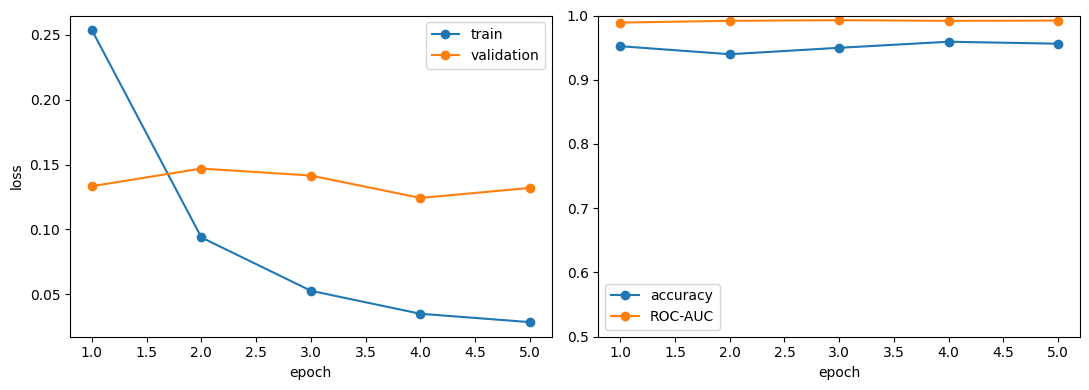

In [7]:
hist = pd.DataFrame(history)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(hist["epoch"], hist["train_loss"], marker="o", label="train")
axes[0].plot(hist["epoch"], hist["val_loss"], marker="o", label="validation")
axes[0].set_xlabel("epoch")
axes[0].set_ylabel("loss")
axes[0].legend()
axes[1].plot(hist["epoch"], hist["val_accuracy"], marker="o", label="accuracy")
axes[1].plot(hist["epoch"], hist["val_auc"], marker="o", label="ROC-AUC")
axes[1].set_xlabel("epoch")
axes[1].set_ylim(0.5, 1.0)
axes[1].legend()
plt.tight_layout()
plt.savefig(ROOT / "results" / f"{RUN_NAME}_curves.png", dpi=100)
plt.show()

## Test (run once, with the best checkpoint)

In [8]:
model.load_state_dict(torch.load(CKPT_DIR / f"{RUN_NAME}.pt", map_location=device))
test_probs = predict(test_loader)
overall = scores(test_set.labels, test_probs)

test_out = test_meta.copy()
test_out["prob_fake"] = test_probs
test_out["correct"] = (test_out["prob_fake"] >= 0.5).astype(int) == test_out["y"]
per_source = test_out.groupby("generator")["correct"].mean()

print("Test:", {k: round(v, 4) for k, v in overall.items()})
print("\nAccuracy per source (Real = correctly called real, others = correctly called fake):")
display(per_source.round(3).to_frame("accuracy"))

results = {
    "run": RUN_NAME,
    "train_sources": TRAIN_SOURCES,
    "epochs": EPOCHS,
    "test": overall,
    "test_per_source_accuracy": per_source.round(4).to_dict(),
    "history": history,
}
with open(ROOT / "results" / f"{RUN_NAME}.json", "w") as f:
    json.dump(results, f, indent=2)
test_out.to_csv(ROOT / "results" / f"{RUN_NAME}_test_predictions.csv", index=False)
print("Saved results and predictions.")

Test: {'loss': 0.1043, 'accuracy': 0.9653, 'auc': 0.9941, 'ap': 0.9941}

Accuracy per source (Real = correctly called real, others = correctly called fake):


,accuracy
generator,
ADM,0.916
GLIDE,0.996
Midjourney,0.936
Real,0.972
SD15,0.982
VQDM,0.970
Wukong,0.954


Saved results and predictions.
